In [67]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from utils.load_data import load_data

### Data Prep & Cleaning

In [68]:
df = load_data(full=False)
df.head(15)

Loading existing sample...


,FOD_ID,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,LATITUDE,LONGITUDE,STATE,STAT_CAUSE_DESCR,FIRE_SIZE,FIRE_SIZE_CLASS
0,201772529,2013,2456557.5,265,0700,37.516010,-119.623040,CA,Lightning,0.10,A
1,158040,2003,2452841.5,202,1045,33.050833,-108.452500,NM,Lightning,0.25,A
2,474869,2006,2454052.5,317,NaN,32.172945,-81.464159,GA,Debris Burning,1.00,B
3,1755089,2008,2454726.5,261,1325,48.059640,-123.186530,WA,Miscellaneous,0.10,A
4,451251,2003,2452917.5,278,NaN,32.241889,-83.045710,GA,Debris Burning,0.07,A
5,1056942,2002,2452384.5,110,NaN,32.618100,-81.014200,SC,Debris Burning,1.00,B
6,1676024,2009,2454912.5,81,1130,37.777370,-85.807380,KY,Campfire,1.00,B
7,19962101,2005,2453734.5,364,1400,35.635000,-88.578333,TN,Debris Burning,1.00,B
8,201818534,2013,2456485.5,193,2300,40.419809,-112.322011,UT,Campfire,0.10,A
9,788087,1996,2450130.5,48,1544,31.490394,-89.543970,MS,Debris Burning,2.00,B


In [69]:
df.columns = df.columns.str.lower()
print(df.isnull().sum())

fod_id                   0
fire_year                0
discovery_date           0
discovery_doy            0
discovery_time      234695
latitude                 0
longitude                0
state                    0
stat_cause_descr         0
fire_size                0
fire_size_class          0
dtype: int64


In [70]:
## Cleaning and transforming some columns

SIZE_LABELS = {"A": "Tiny", "B": "Small", "C": "Medium", "D": "Large",
                 "E": "Very large", "F": "Major", "G": "Catastrophic"}
df["fire_size_label"] = pd.Categorical(
    df["fire_size_class"].map(SIZE_LABELS),
    categories=list(SIZE_LABELS.values()), ordered=True,
)

df["discovery_hour"] = pd.to_numeric(df["discovery_time"], errors="coerce") // 100
df = df.drop(columns="discovery_time")


d = pd.to_datetime(df["discovery_date"], unit="D", origin="julian")
df["month"] = d.dt.month
df["day_of_week"] = d.dt.day_of_week
df = df.drop(columns="discovery_date")

In [71]:
df.head()

,fod_id,fire_year,discovery_doy,latitude,longitude,state,stat_cause_descr,fire_size,fire_size_class,fire_size_label,discovery_hour,month,day_of_week
0,201772529,2013,265,37.516010,-119.623040,CA,Lightning,0.10,A,Tiny,7.0,9,6
1,158040,2003,202,33.050833,-108.452500,NM,Lightning,0.25,A,Tiny,10.0,7,0
2,474869,2006,317,32.172945,-81.464159,GA,Debris Burning,1.00,B,Small,NaN,11,0
3,1755089,2008,261,48.059640,-123.186530,WA,Miscellaneous,0.10,A,Tiny,13.0,9,2
4,451251,2003,278,32.241889,-83.045710,GA,Debris Burning,0.07,A,Tiny,NaN,10,6


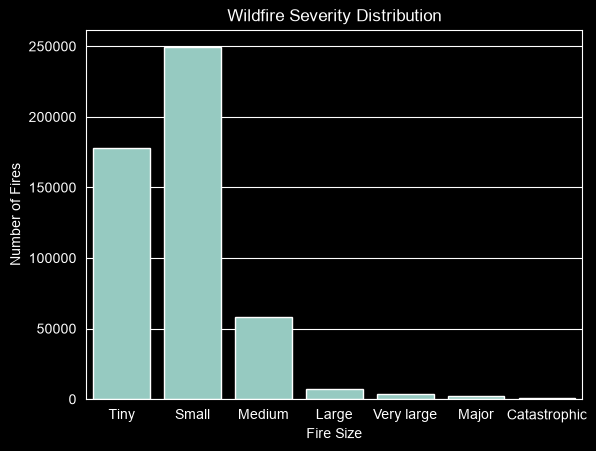

In [72]:
sns.countplot(
    data=df,
    x="fire_size_label",
    order=list(SIZE_LABELS.values()),
)

plt.title("Wildfire Severity Distribution")
plt.xlabel("Fire Size")
plt.ylabel("Number of Fires")
plt.show()

In [73]:
distribution_by_year = pd.crosstab(
    df["fire_year"],
    df["fire_size_label"],
    normalize="index",
) * 100

display(distribution_by_year.round(2))

fire_size_label,Tiny,Small,Medium,Large,Very large,Major,Catastrophic
fire_year,,,,,,,
1992,37.84,48.44,11.74,1.17,0.47,0.26,0.08
1993,33.53,52.25,11.91,1.31,0.65,0.26,0.09
1994,36.62,48.87,11.39,1.55,0.87,0.53,0.17
1995,33.56,51.53,12.43,1.44,0.68,0.31,0.05
1996,33.08,50.27,13.34,1.56,1.03,0.45,0.28
1997,35.61,51.85,10.72,1.13,0.40,0.19,0.12
1998,34.52,51.63,11.49,1.38,0.64,0.24,0.10
1999,31.08,53.27,12.86,1.48,0.72,0.41,0.18
2000,33.85,50.13,12.63,1.71,0.89,0.53,0.25


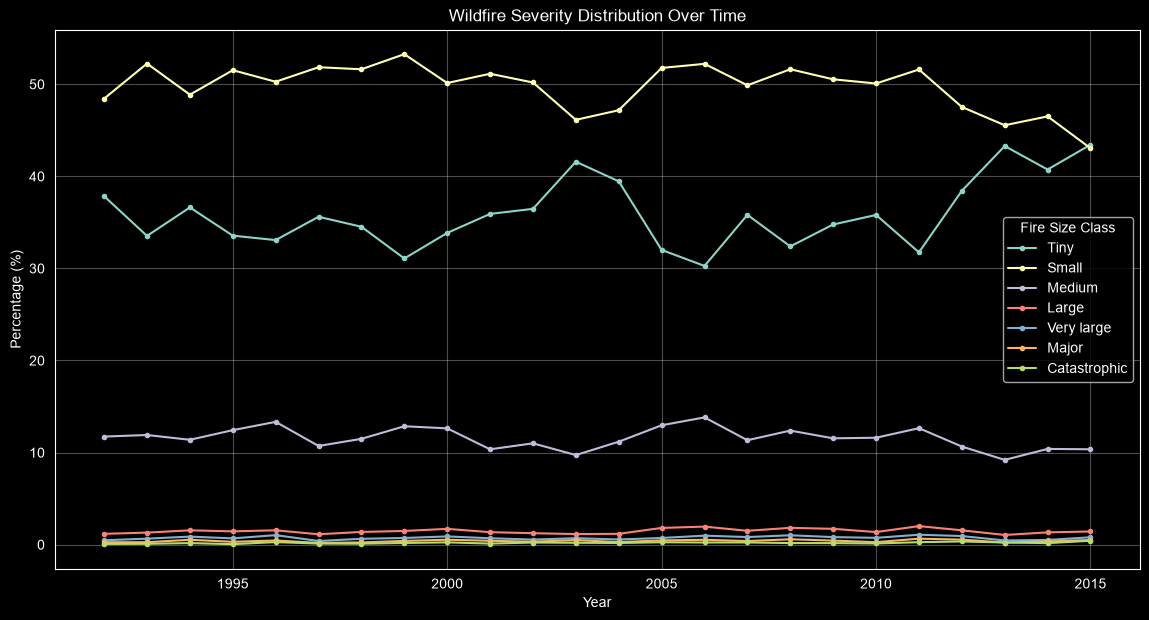

In [74]:
distribution_by_year.plot(
    figsize=(14, 7),
    kind="line",
    marker=".",
)

plt.title("Wildfire Severity Distribution Over Time")
plt.xlabel("Year")
plt.ylabel("Percentage (%)")
plt.legend(title="Fire Size Class")
plt.grid(alpha=0.3)
plt.show()

In [75]:
df.columns

Index(['fod_id', 'fire_year', 'discovery_doy', 'latitude', 'longitude',
       'state', 'stat_cause_descr', 'fire_size', 'fire_size_class',
       'fire_size_label', 'discovery_hour', 'month', 'day_of_week'],
      dtype='str')

### Target / feature split and train-validation-test split

In [78]:
from sklearn.model_selection import train_test_split

TARGET = "fire_size_class"
LEAKY = ["fire_size", "fire_size_label"]

y = df[TARGET]
X = df.drop(columns=[TARGET, *LEAKY])

# 60% train / 20% validation / 20% test, stratified so rare classes appear in every split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

print("\nClass distribution (%) per split:")
print(
    pd.DataFrame({
        "train": y_train.value_counts(normalize=True),
        "val": y_val.value_counts(normalize=True),
        "test": y_test.value_counts(normalize=True),
    }).mul(100).round(2).sort_index()
)



Class distribution (%) per split:
                 train    val   test
fire_size_class                     
A                35.58  35.58  35.58
B                49.87  49.87  49.87
C                11.68  11.68  11.68
D                 1.50   1.50   1.50
E                 0.76   0.76   0.76
F                 0.41   0.41   0.41
G                 0.20   0.20   0.20


### EDA (training set only)

Exploring only `X_train` so nothing from the validation/test sets influences our decisions. "Large" below means classes D-G (100+ acres).

In [79]:
train = X_train.assign(fire_size_class=y_train)
train["fire_size_label"] = pd.Categorical(
    train["fire_size_class"].map(SIZE_LABELS),
    categories=list(SIZE_LABELS.values()), ordered=True,
)
train["is_large"] = train["fire_size_class"].isin(list("DEFG"))

print(f"Share of large fires (class D-G): {train['is_large'].mean():.2%}")

Share of large fires (class D-G): 2.87%


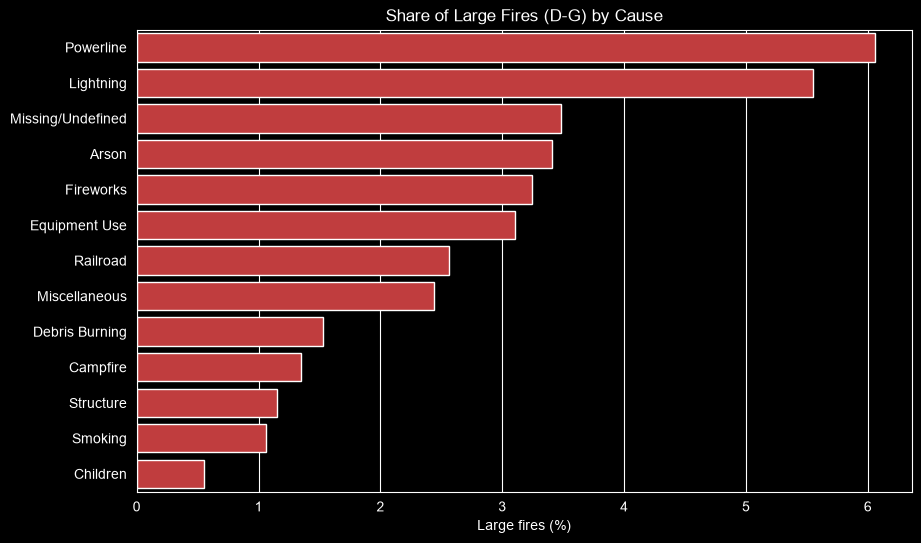

In [80]:
# Share of large fires by cause
large_by_cause = (
    train.groupby("stat_cause_descr")["is_large"].mean().mul(100).sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=large_by_cause.values, y=large_by_cause.index, color="tab:red")
plt.title("Share of Large Fires (D-G) by Cause")
plt.xlabel("Large fires (%)")
plt.ylabel("")
plt.show()

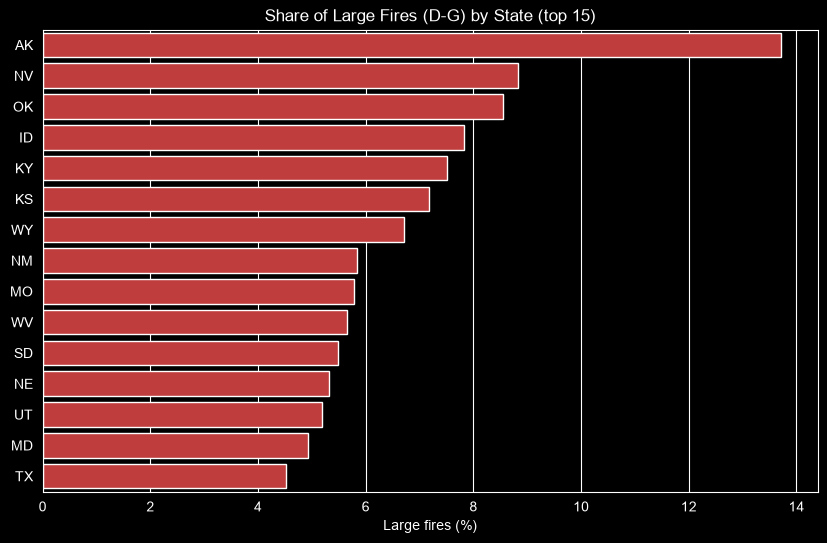

In [81]:
# Share of large fires by state (states with at least 500 fires, top 15)
by_state = train.groupby("state")["is_large"].agg(["mean", "size"])
by_state = by_state[by_state["size"] >= 500]["mean"].mul(100).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=by_state.values, y=by_state.index, color="tab:red")
plt.title("Share of Large Fires (D-G) by State (top 15)")
plt.xlabel("Large fires (%)")
plt.ylabel("")
plt.show()

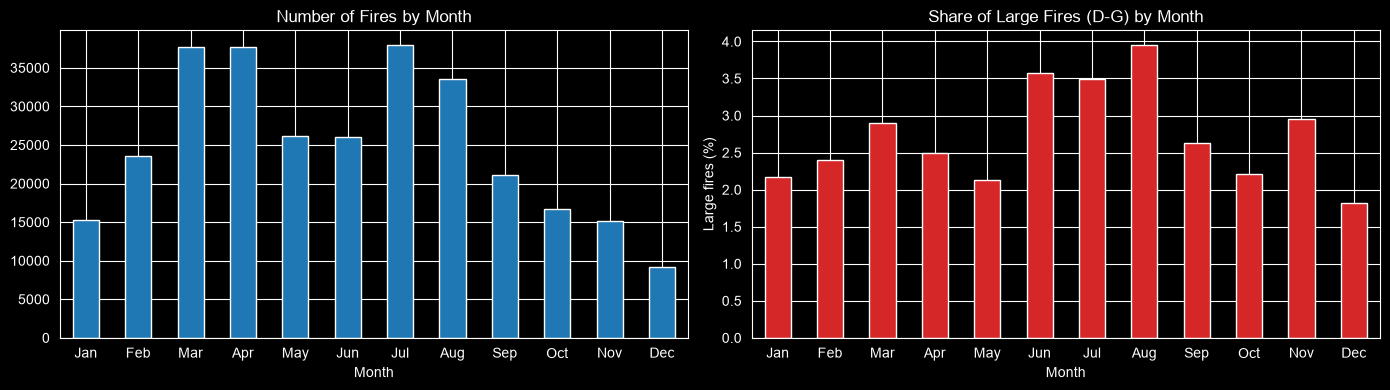

In [90]:
# Seasonality: how many fires, and how many of them are large, per month
import calendar

month_labels = list(calendar.month_abbr)[1:]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

train["month"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="tab:blue"
)
axes[0].set_title("Number of Fires by Month")
axes[0].set_xlabel("Month")

train.groupby("month")["is_large"].mean().mul(100).plot(
    kind="bar", ax=axes[1], color="tab:red"
)
axes[1].set_title("Share of Large Fires (D-G) by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Large fires (%)")

for ax in axes:
    ax.set_xticklabels(month_labels, rotation=0)

plt.tight_layout()
plt.show()

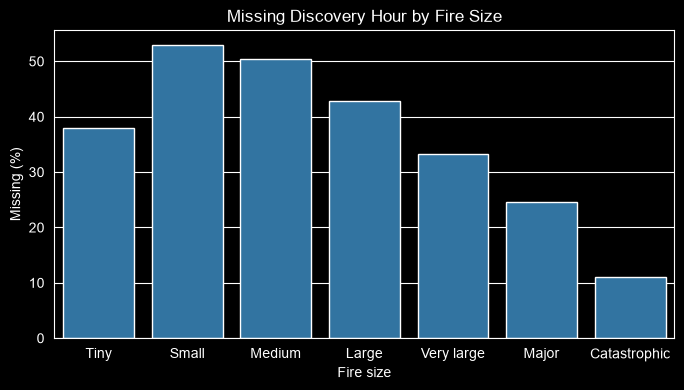

In [84]:
# Is a missing discovery_hour related to fire size?
missing_by_class = (
    train["discovery_hour"].isna().groupby(train["fire_size_label"], observed=True).mean().mul(100)
)

plt.figure(figsize=(8, 4))
sns.barplot(x=missing_by_class.index.astype(str), y=missing_by_class.values, color="tab:blue")
plt.title("Missing Discovery Hour by Fire Size")
plt.xlabel("Fire size")
plt.ylabel("Missing (%)")
plt.show()

### Preprocessing and baselines

Metrics are computed on the validation set. Accuracy is misleading here (class B alone is about 50%), so **macro-F1** is our main metric.

In [85]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical = ["state", "stat_cause_descr"]
numeric = [c for c in X_train.columns if c not in categorical]

# Missing discovery_hour: fill with the median and keep an indicator column (needed for linear models)
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

results = {}


def evaluate(name, model):
    """Score a fitted model on the validation set and store the metrics."""
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)
    results[name] = {
        "accuracy": accuracy_score(y_val, pred),
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "weighted_f1": f1_score(y_val, pred, average="weighted"),
        "roc_auc_ovr": roc_auc_score(y_val, proba, multi_class="ovr", average="macro", labels=model.classes_),
    }
    print(classification_report(y_val, pred, zero_division=0))
    return pd.DataFrame(results).T.round(3)

In [86]:
# Baseline 1: always predict the most frequent class (B)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("always B", dummy)

              precision    recall  f1-score   support

           A       0.00      0.00      0.00     35576
           B       0.50      1.00      0.67     49874
           C       0.00      0.00      0.00     11681
           D       0.00      0.00      0.00      1499
           E       0.00      0.00      0.00       758
           F       0.00      0.00      0.00       413
           G       0.00      0.00      0.00       199

    accuracy                           0.50    100000
   macro avg       0.07      0.14      0.10    100000
weighted avg       0.25      0.50      0.33    100000



,accuracy,macro_f1,weighted_f1,roc_auc_ovr
always B,0.499,0.095,0.332,0.5


In [87]:
# Baseline 2: logistic regression with balanced class weights
log_reg = make_pipeline(
    preprocess,
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
log_reg.fit(X_train, y_train)
evaluate("logistic regression (balanced)", log_reg)

              precision    recall  f1-score   support

           A       0.57      0.43      0.49     35576
           B       0.65      0.31      0.42     49874
           C       0.24      0.34      0.28     11681
           D       0.03      0.24      0.06      1499
           E       0.03      0.15      0.04       758
           F       0.01      0.19      0.02       413
           G       0.01      0.64      0.02       199

    accuracy                           0.35    100000
   macro avg       0.22      0.33      0.19    100000
weighted avg       0.55      0.35      0.42    100000



,accuracy,macro_f1,weighted_f1,roc_auc_ovr
always B,0.499,0.095,0.332,0.500
logistic regression (balanced),0.354,0.191,0.417,0.735


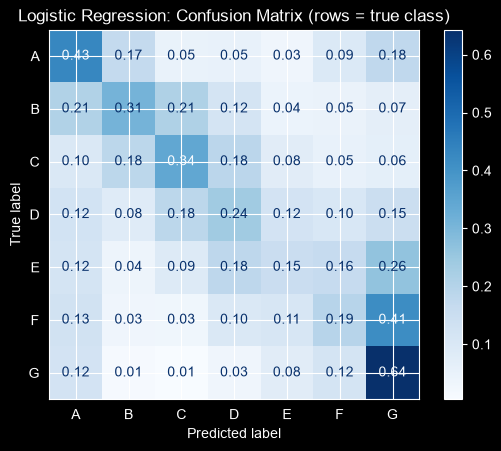

In [88]:
ConfusionMatrixDisplay.from_predictions(
    y_val, log_reg.predict(X_val), normalize="true", values_format=".2f", cmap="Blues",
)
plt.title("Logistic Regression: Confusion Matrix (rows = true class)")
plt.show()